In [ ]:
import os
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from astropy.coordinates import SkyCoord
import astropy.units as u

from astrodendro import Dendrogram

from skimage import measure
from skimage.measure import regionprops
from skimage.segmentation import find_boundaries

from tqdm.notebook import tqdm

In [2]:
def percentile_norm(img, pmin=1, pmax=99):
    x = np.array(img, dtype=float, copy=True)
    x[~np.isfinite(x)] = np.nan

    lo, hi = np.nanpercentile(x, [pmin, pmax])
    x = (x - lo) / (hi - lo)
    x = np.clip(x, 0, 1)
    return x 

In [3]:
def clean_map(x):
    y = np.array(x, dtype=float, copy=True)
    y[~np.isfinite(y)] = 0.0
    y[y < 0] = 0.0
    return y

In [4]:
def mask_pn_cat(cat, wcs, shape, radius_factor=2.0):
    mask = np.zeros(shape, dtype=bool)

    coords = SkyCoord(cat["RAdeg"].values * u.deg, cat["DEdeg"].values * u.deg)
    x, y = wcs.world_to_pixel(coords)

    yy, xx = np.indices(shape)

    for xi, yi, fwhm_arcsec in zip(x, y, cat["FWHM"].values):
        if not np.isfinite(xi) or not np.isfinite(yi):
            continue

        r_pix = radius_factor * fwhm_arcsec / pix_scale
        source_mask = (xx - xi)**2 + (yy - yi)**2 <= r_pix**2
        mask |= source_mask

    return mask

In [5]:
'''
def det_map(ha, ha_err, oiii, oiii_err, sii, sii_err, snr_min):

    fluxes = [ha, oiii, sii]
    errors = [ha_err, oiii_err, sii_err]

    detection_sq = np.zeros_like(ha, dtype=float)

    for flux, err in zip(fluxes, errors):
        flux = np.asarray(flux, dtype=float)
        err = np.asarray(err, dtype=float)

        valid = np.isfinite(flux) & np.isfinite(err) & (err > 0)

        snr = np.zeros_like(flux, dtype=float)
        snr[valid] = flux[valid] / err[valid]

        snr = np.where(snr > snr_min, snr, 0.0)

        detection_sq += snr**2

    detection = np.sqrt(detection_sq)
    detection[~np.isfinite(detection)] = 0.0

    return detection
'''

def global_noise(err, method="median"):
    err = np.asarray(err, dtype=float)

    valid = np.isfinite(err) & (err > 0)
    vals = err[valid]

    if method == "median":
        return np.nanmedian(vals)

    elif method == "rms":
        return np.sqrt(np.nanmedian(vals**2))

    elif method == "percentile":
        return np.nanpercentile(vals, 60)

    else:
        return np.nanmean(vals)


def det_map(ha, ha_err, oiii, oiii_err, sii, sii_err, snr_min=0.0, noise_method="median"):

    fluxes = [ha, oiii, sii]
    errors = [ha_err, oiii_err, sii_err]

    noises = [global_noise(err, method=noise_method) for err in errors]

    detection_sq = np.zeros_like(ha, dtype=float)

    for flux, noise in zip(fluxes, noises):
        flux = np.asarray(flux, dtype=float)

        valid = np.isfinite(flux)

        snr = np.zeros_like(flux, dtype=float)
        snr[valid] = flux[valid] / noise

        snr = np.clip(snr, 0, None)

        if snr_min > 0:
            snr = np.where(snr > snr_min, snr, 0.0)

        detection_sq += snr**2

    detection = np.sqrt(detection_sq)
    detection[~np.isfinite(detection)] = 0.0

    return detection

In [6]:
def comp_dendro(input_den, value, delta, npix):
    d = Dendrogram.compute(
        input_den,
        min_value=value,
        min_delta=delta,
        min_npix=npix)

    labels_dendro = np.zeros(input_den.shape, dtype=np.int32)
    for i, leaf in enumerate(d.leaves, start=1):
        labels_dendro[leaf.get_mask()] = i

    print(f"Astrodendro leaves count: {len(d.leaves)}")

    show = labels_dendro.astype(float)
    show[show == 0] = np.nan
    return labels_dendro, show

In [7]:
def conv (labels, detection, npix):
    binary_mask = labels > 0

    smooth_mask = ndi.gaussian_filter(binary_mask.astype(float), sigma=2.0)
    smooth_mask = smooth_mask > 0.4
    
    connected_labels, n_connected = ndi.label(smooth_mask)
    
    print(f"Number of regions after smoothing: {n_connected}")
    
    segm = SegmentationImage(connected_labels.astype(np.int32))
    deblend_data = clean_map(detection)
    
    labels_final = deblend_sources(
        deblend_data, segm, n_pixels=npix,
        n_levels=32, contrast=0.001)
    
    print(f"final deblended regions: {labels_final.data.astype(np.int32).max()}")

    show = labels_final.data.astype(np.int32).astype(float)
    show[show == 0] = np.nan

    return labels_final, show
    

In [8]:
def safe_ratio(num, den):
    out = np.full_like(num, np.nan, dtype=float)
    mask = np.isfinite(num) & np.isfinite(den) & (den > 0) & (num > 0)
    out[mask] = num[mask] / den[mask]
    return out

In [9]:
def sum_in_mask(arr, mask):
    x = np.array(arr, dtype=float)
    good = np.isfinite(x)
    return np.nansum(x[mask & good])

In [10]:
def err_sum_in_mask(err, mask):
    e = np.array(err, dtype=float)
    good = np.isfinite(e) & (e > 0)
    return np.sqrt(np.nansum(e[mask & good]**2))

In [11]:
def classify_bpt(log_nii_ha, log_oiii_hb):
    if not (np.isfinite(log_nii_ha) and np.isfinite(log_oiii_hb)):
        return "unclassified_BPT"

    kewley = 0.61 / (log_nii_ha - 0.47) + 1.19
    kauff  = 0.61 / (log_nii_ha - 0.05) + 1.30

    if log_nii_ha < 0.05 and log_oiii_hb < kauff:
        return "HII_BPT_clean"
    elif log_nii_ha < 0.47 and log_oiii_hb < kewley:
        return "HII_BPT_possible"
    else:
        return "non_HII_BPT"

In [13]:
def plot_region_contours(base_image, labels_data, region_ids, title, contour_color="red"):
    fig, ax = plt.subplots(figsize=(10, 5))
    
    ax.imshow(base_image, origin="lower")

    count_drawn = 0

    for rid in region_ids:
        mask = labels_data == rid

        if not np.any(mask):
            continue

        contours = measure.find_contours(mask.astype(float), level=0.5)

        for contour in contours:
            ax.plot(contour[:, 1], contour[:, 0], color=contour_color, linewidth=1.3)

        count_drawn += 1

    ax.set_title(f"{title} ({count_drawn} regions)")
    ax.set_xlabel("x [pix]")
    ax.set_ylabel("y [pix]")
    plt.tight_layout()
    plt.show()

In [14]:
def plot_single_region(image, labels_data, region_id, title_prefix="", contour_color="red", pad=20):
    mask = labels_data == region_id

    yy, xx = np.where(mask)
    y0, y1 = yy.min(), yy.max()
    x0, x1 = xx.min(), xx.max()

    y0p = max(0, y0 - pad)
    y1p = min(labels_data.shape[0], y1 + pad + 1)
    x0p = max(0, x0 - pad)
    x1p = min(labels_data.shape[1], x1 + pad + 1)

    img_cut = image[y0p:y1p, x0p:x1p]
    mask_cut = mask[y0p:y1p, x0p:x1p]

    plt.figure(figsize=(6, 6))
    plt.imshow(img_cut, origin="lower")
    plt.contour(mask_cut.astype(float), levels=[0.5], colors=contour_color, linewidths=1.5)
    plt.title(f"{title_prefix} Region {region_id}")
    plt.axis("off")
    plt.show()

In [15]:
def make_segmentation_qa(labels_data, detection, pn_mask=None):
    rows = []
    ny, nx = labels_data.shape

    for prop in regionprops(labels_data, intensity_image=detection):
        lab = prop.label
        mask = labels_data == lab
        npix = int(mask.sum())

        if npix == 0:
            continue

        ycen, xcen = prop.centroid
        ra, dec = wcs.wcs_pix2world(xcen, ycen, 0)

        minr, minc, maxr, maxc = prop.bbox
        edge_touching = (minr == 0) or (minc == 0) or (maxr == ny) or (maxc == nx)

        major = prop.axis_major_length
        minor = prop.axis_minor_length
        elongation = major / minor if minor > 0 else np.nan

        det_vals = detection[mask]
        det_vals = det_vals[np.isfinite(det_vals)]

        det_peak = np.nanmax(det_vals) if det_vals.size else np.nan
        det_median = np.nanmedian(det_vals) if det_vals.size else np.nan
        det_p90 = np.nanpercentile(det_vals, 90) if det_vals.size else np.nan

        F_ha = sum_in_mask(ha, mask)
        F_oiii = sum_in_mask(oiii, mask)
        F_sii = sum_in_mask(sii, mask)

        E_ha = err_sum_in_mask(ha_err, mask)
        E_oiii = err_sum_in_mask(oiii_err, mask)
        E_sii = err_sum_in_mask(sii_err, mask)

        sn_ha = F_ha / E_ha if E_ha > 0 else np.nan
        sn_oiii = F_oiii / E_oiii if E_oiii > 0 else np.nan
        sn_sii = F_sii / E_sii if E_sii > 0 else np.nan

        if pn_mask is not None:
            pn_overlap_npix = int(np.sum(mask & pn_mask))
            pn_overlap_frac = pn_overlap_npix / npix
        else:
            pn_overlap_npix = 0
            pn_overlap_frac = 0.0

        rows.append({
            "region_id": lab,
            "npix": npix,
            "area_arcsec2": npix * pix_scale**2,
            "r_eq_pix": np.sqrt(npix / np.pi),
            "r_eq_arcsec": np.sqrt(npix / np.pi) * pix_scale,
            "x": xcen,
            "y": ycen,
            "ra": ra,
            "dec": dec,
            "bbox_width": maxc - minc,
            "bbox_height": maxr - minr,
            "edge_touching": edge_touching,
            "major_axis_pix": major,
            "minor_axis_pix": minor,
            "elongation": elongation,
            "eccentricity": prop.eccentricity,
            "det_peak": det_peak,
            "det_median": det_median,
            "det_p90": det_p90,
            "F_ha": F_ha,
            "F_oiii": F_oiii,
            "F_sii": F_sii,
            "sn_ha": sn_ha,
            "sn_oiii": sn_oiii,
            "sn_sii": sn_sii,
            "pn_overlap_npix": pn_overlap_npix,
            "pn_overlap_frac": pn_overlap_frac})

    return pd.DataFrame(rows)

In [55]:
def make_local_annulus(labels_data, region_id, qa_lookup,
    label_slices, inner_factor, outer_factor,
    min_inner_pix=3, min_outer_pix=6, extra_pad=2):
    
    row = qa_lookup.loc[region_id]
    r_eq_pix = row["r_eq_pix"]

    inner_rad = int(np.ceil(max(inner_factor * r_eq_pix, min_inner_pix)))
    outer_rad = int(np.ceil(max(outer_factor * r_eq_pix, min_outer_pix)))

    if outer_rad <= inner_rad:
        outer_rad = inner_rad + 2

    base_slc = label_slices[region_id - 1]

    if base_slc is None:
        return None, None, None

    yslice, xslice = base_slc
    ny, nx = labels_data.shape

    y0 = max(yslice.start - outer_rad - extra_pad, 0)
    y1 = min(yslice.stop  + outer_rad + extra_pad, ny)
    x0 = max(xslice.start - outer_rad - extra_pad, 0)
    x1 = min(xslice.stop  + outer_rad + extra_pad, nx)

    slc = np.s_[y0:y1, x0:x1]
    labels_crop = labels_data[slc]

    src_crop = labels_crop == region_id

    if not np.any(src_crop):
        return None, None, None

    # Distance from every non-source pixel to the nearest source pixel
    dist = ndi.distance_transform_edt(~src_crop)

    ann_crop = ((dist > inner_rad) & (dist <= outer_rad) & (labels_crop == 0))

    return src_crop, ann_crop, slc

In [17]:
def expand_slice(slc, image_shape, pad=40):
    yslc, xslc = slc
    ny, nx = image_shape[:2]

    y0 = max(yslc.start - pad, 0)
    y1 = min(yslc.stop + pad, ny)
    x0 = max(xslc.start - pad, 0)
    x1 = min(xslc.stop + pad, nx)

    return np.s_[y0:y1, x0:x1]

In [18]:
def show_source_annulus(image, source_crop, annulus_crop,
    slc, labels_data=None, title="",
    show_all_regions=True, pad=40,):

    plot_slc = expand_slice(slc, image.shape, pad=pad)

    img_view = image[plot_slc]

    view_shape = img_view.shape[:2]
    src_view = np.zeros(view_shape, dtype=bool)
    ann_view = np.zeros(view_shape, dtype=bool)

    y_offset = slc[0].start - plot_slc[0].start
    x_offset = slc[1].start - plot_slc[1].start

    y_size, x_size = source_crop.shape

    src_view[y_offset:y_offset + y_size,
        x_offset:x_offset + x_size] = source_crop

    ann_view[y_offset:y_offset + y_size,
        x_offset:x_offset + x_size] = annulus_crop

    plt.figure(figsize=(8, 8))
    plt.imshow(img_view, origin="lower")

    if labels_data is not None and show_all_regions:
        lab_view = labels_data[plot_slc]
        all_boundaries = find_boundaries(lab_view, mode="outer")

        plt.contour(all_boundaries.astype(float),
            levels=[0.5], colors="white",
            linewidths=0.5, alpha=0.45)

    if np.any(src_view):
        plt.contour(
            src_view.astype(float),
            levels=[0.5],
            colors="lime",
            linewidths=2.0)

    if np.any(ann_view):
        plt.contour(
            ann_view.astype(float),
            levels=[0.5],
            colors="red",
            linewidths=1.3)

    plt.title(title)
    plt.axis("off")
    plt.show()

In [19]:
pix_scale = 0.2
psf_fwhm_arcsec = 0.85
psf_fwhm_pix = psf_fwhm_arcsec / pix_scale

In [20]:
path = "/Users/golta/Desktop/Uni/Thesis/Model Selection/Classic/ADP.2025-07-06T07_52_11.876.fits"
hdul = fits.open(path, memmap=True)
for i, h in enumerate(hdul):
        print(f"{i:3d}  {h.name:25s}")
        if i==30:
            break

  0  PRIMARY                  
  1  ID                       
  2  FLUX                     
  3  SNR                      
  4  SNRBIN                   
  5  BIN_ID                   
  6  V_STARS                  
  7  FORM_ERR_V_STARS         
  8  SIGMA_STARS              
  9  FORM_ERR_SIGMA_STARS     
 10  H3_STARS                 
 11  FORM_ERR_H3_STARS        
 12  H4_STARS                 
 13  FORM_ERR_H4_STARS        
 14  CHI2_TOT                 
 15  HEII4685_FLUX            
 16  HEII4685_FLUX_ERR        
 17  HEII4685_VEL             
 18  HEII4685_VEL_ERR         
 19  HEII4685_SIGMA           
 20  HEII4685_SIGMA_ERR       
 21  HEII4685_SIGMA_CORR      
 22  HEII4685_MOM0            
 23  HEII4685_MOM0_ERR        
 24  HEII4685_MOM1            
 25  HEII4685_MOM1_ERR        
 26  HEII4685_MOM2            
 27  HEII4685_MOM2_ERR        
 28  HB4861_FLUX              
 29  HB4861_FLUX_ERR          
 30  HB4861_VEL               


In [21]:
ha = hdul["HA6562_FLUX"].data
hb = hdul["HB4861_FLUX"].data
oiii = hdul["OIII5006_FLUX"].data
nii = hdul["NII6583_FLUX"].data
sii6716 = hdul["SII6716_FLUX"].data
sii6730 = hdul["SII6730_FLUX"].data
sii = sii6716 + sii6730

ha_err = hdul["HA6562_FLUX_ERR"].data
hb_err = hdul["HB4861_FLUX_ERR"].data
oiii_err = hdul["OIII5006_FLUX_ERR"].data
nii_err = hdul["NII6583_FLUX_ERR"].data
sii6716_err = hdul["SII6716_FLUX_ERR"].data
sii6730_err = hdul["SII6730_FLUX_ERR"].data
sii_err = np.sqrt(sii6716_err**2 + sii6730_err**2)

In [22]:
header = hdul["HA6562_FLUX"].header
wcs = WCS(header)

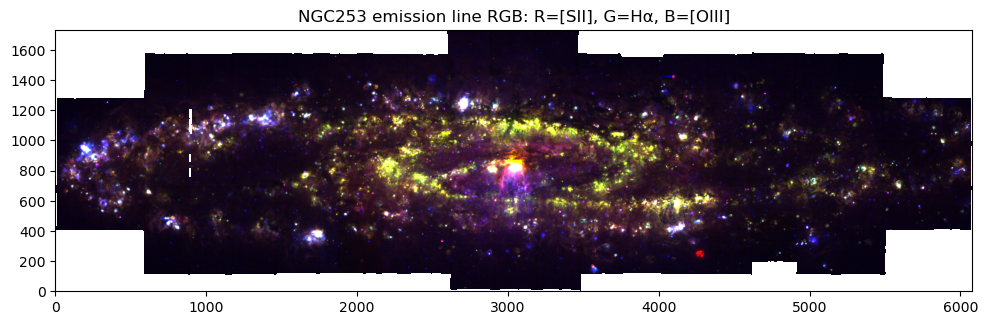

In [23]:
rgb = np.dstack([percentile_norm(sii),percentile_norm(ha),percentile_norm(oiii)])

plt.figure(figsize=(10, 5))
plt.imshow(rgb, origin="lower")
plt.title("NGC253 emission line RGB: R=[SII], G=H\u03B1, B=[OIII]")
plt.tight_layout()
plt.show()

In [24]:
pn_cat = pd.read_csv("/Users/golta/Desktop/Uni/Thesis/Model Selection/Classic/PN_CAT.csv")

pn_mask = mask_pn_cat(pn_cat, wcs, ha.shape, radius_factor=2.0)

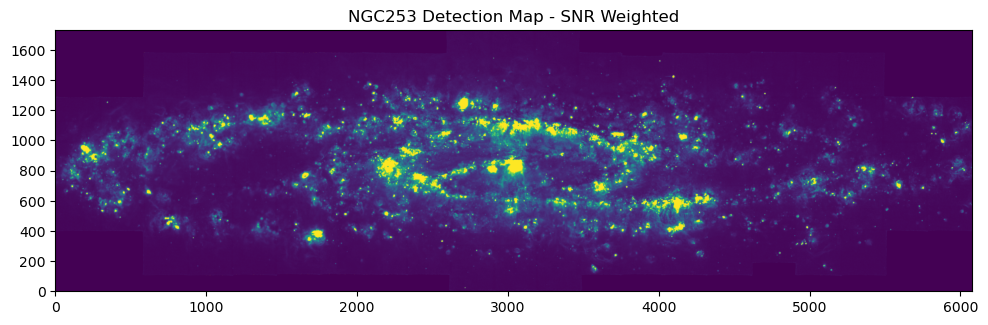

In [25]:
detection = det_map(ha, ha_err, oiii, oiii_err, sii, sii_err, snr_min=0.0, noise_method="median")
#detection[pn_mask] = 0.0

plt.figure(figsize=(10, 5))
plt.imshow(percentile_norm(detection), origin="lower")
plt.title("NGC253 Detection Map - SNR Weighted")
plt.tight_layout()
plt.show()

In [26]:
labels_1, i1 = comp_dendro(detection, 3.0, 3.0, 500)
labels_2, i2 = comp_dendro(detection, 15.0, 3.0, 500)
labels_3, i3 = comp_dendro(detection, 15.0, 3.0, 300)
labels_4, i4= comp_dendro(detection, 30.0, 3.0, 500)

Astrodendro leaves count: 1254
Astrodendro leaves count: 662
Astrodendro leaves count: 1102
Astrodendro leaves count: 495


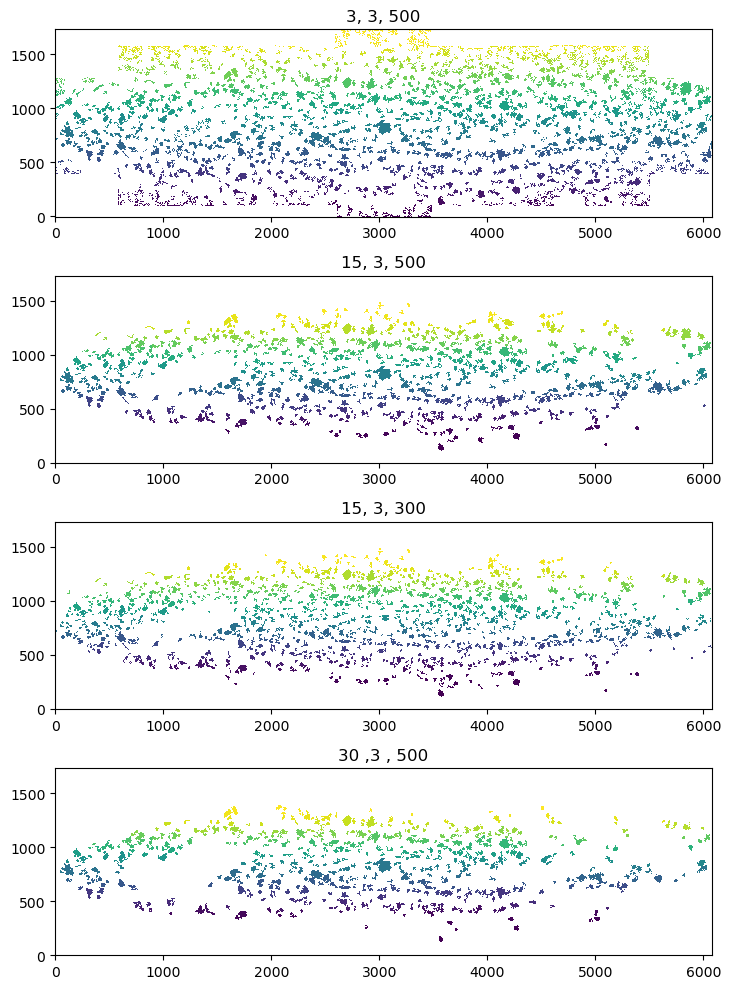

In [27]:
fig = plt.figure(figsize=(20,10))

ax = fig.add_subplot(411)
ax.imshow(i1, origin='lower', interpolation='none')
ax.set_title('3, 3, 500')

ax = fig.add_subplot(412)
ax.imshow(i2, origin='lower', interpolation='none')
ax.set_title('15, 3, 500')

ax = fig.add_subplot(413)
ax.imshow(i3, origin='lower', interpolation='none')
ax.set_title('15, 3, 300')

ax = fig.add_subplot(414)
ax.imshow(i4, origin='lower', interpolation='none')
ax.set_title('30 ,3 , 500')

plt.tight_layout()
plt.show()

In [28]:
conv_label_1, show_1 = conv(labels_1, detection, 500)
conv_label_2, show_2 = conv(labels_2, detection, 500)
conv_label_3, show_3 = conv(labels_3, detection, 300)
conv_label_4, show_4= conv(labels_4, detection, 500)

Number of regions after smoothing: 989


Deblending:   0%|          | 0/576 [00:00<?, ?it/s]

final deblended regions: 1158
Number of regions after smoothing: 526


Deblending:   0%|          | 0/331 [00:00<?, ?it/s]

final deblended regions: 644
Number of regions after smoothing: 862


Deblending:   0%|          | 0/529 [00:00<?, ?it/s]

final deblended regions: 1045
Number of regions after smoothing: 384


Deblending:   0%|          | 0/245 [00:00<?, ?it/s]

final deblended regions: 477


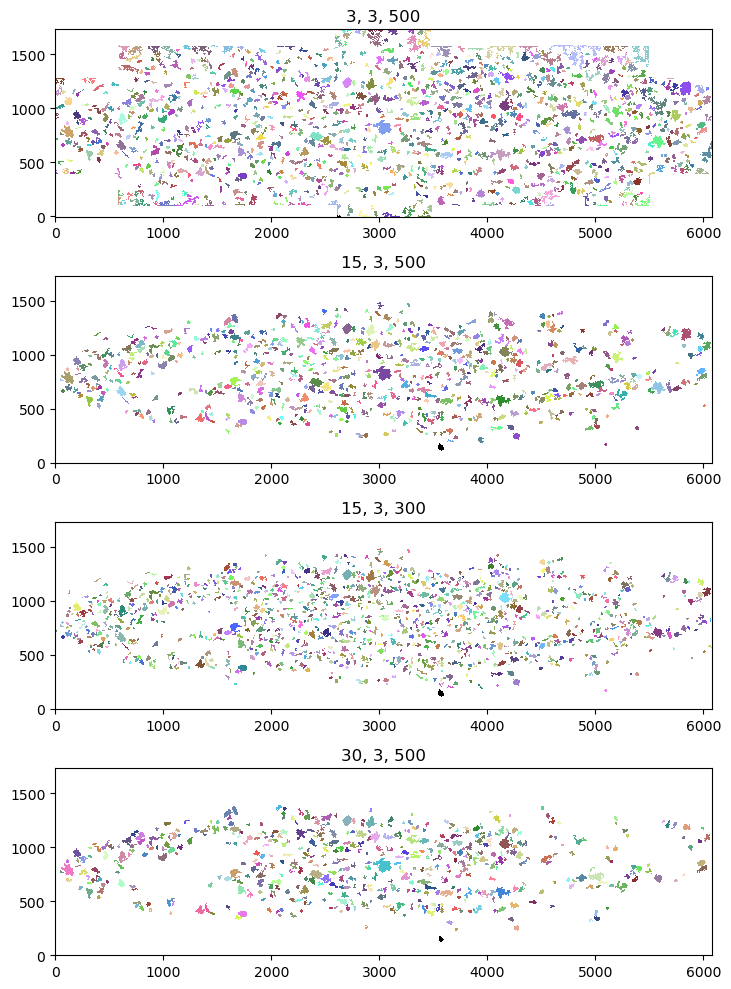

In [29]:
fig = plt.figure(figsize=(20,10))

ax = fig.add_subplot(411)
ax.imshow(show_1, cmap=conv_label_1.make_cmap(), origin='lower', interpolation='none')
ax.set_title('3, 3, 500')

ax = fig.add_subplot(412)
ax.imshow(show_2, cmap=conv_label_2.make_cmap(), origin='lower', interpolation='none')
ax.set_title('15, 3, 500')

ax = fig.add_subplot(413)
ax.imshow(show_3, cmap=conv_label_3.make_cmap(), origin='lower', interpolation='none')
ax.set_title('15, 3, 300')

ax = fig.add_subplot(414)
ax.imshow(show_4, cmap=conv_label_4.make_cmap(), origin='lower', interpolation='none')
ax.set_title('30, 3, 500')

plt.tight_layout()
plt.show()

In [30]:
labels_data = conv_label_2.data.astype(np.int32)

sii_oiii = safe_ratio(sii, oiii)
log_sii_oiii = np.log10(sii_oiii)

sii_ha = safe_ratio(sii, ha)
log_sii_ha = np.log10(sii_ha)

valid_ipm = (np.isfinite(log_sii_oiii) & np.isfinite(log_sii_ha))

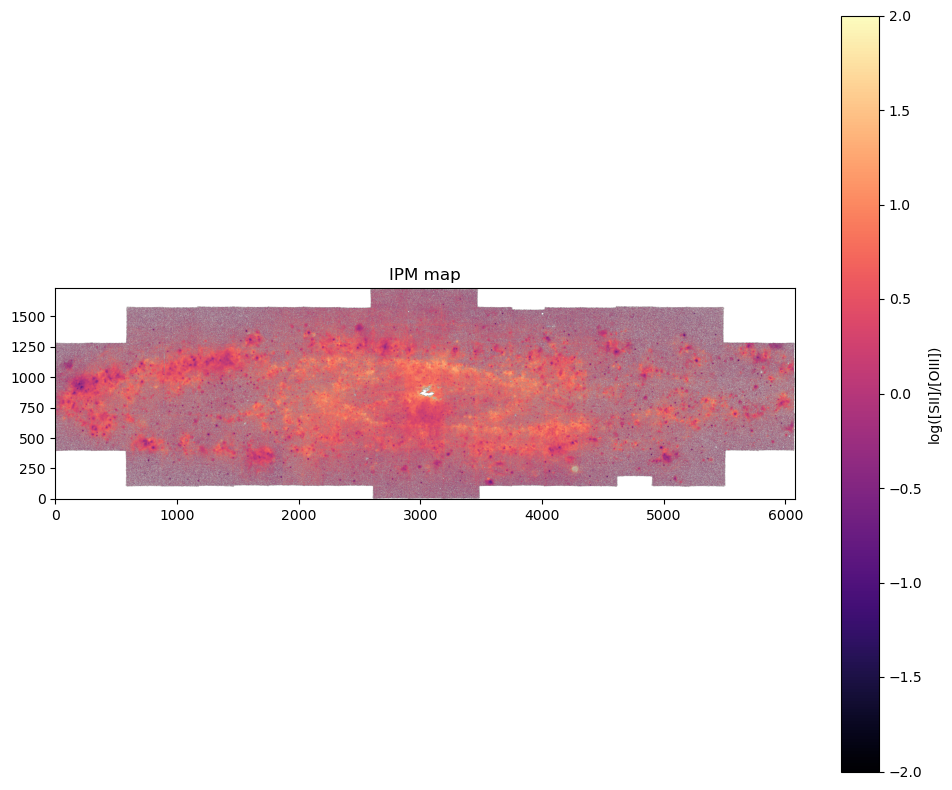

In [31]:
plt.figure(figsize=(10, 8))
plt.imshow(log_sii_oiii, origin="lower", cmap="magma", vmin=-2, vmax=2)
plt.colorbar(label=r"log([SII]/[OIII])")
plt.title("IPM map")
plt.tight_layout()
plt.show()

In [32]:
qa = make_segmentation_qa(labels_data, detection, pn_mask=None)

In [33]:
qa[["npix",
    "r_eq_arcsec",
    "elongation",
    "det_peak",
    "det_median",
    "sn_ha",
    "sn_oiii",
    "sn_sii",
    "pn_overlap_frac"]].describe()

,npix,r_eq_arcsec,elongation,det_peak,det_median,sn_ha,sn_oiii,sn_sii,pn_overlap_frac
count,644.000000,644.000000,643.000000,644.000000,644.000000,644.000000,644.000000,644.000000,644.0
mean,1607.254658,4.266663,1.778334,556.487467,78.041678,1631.332960,267.178966,709.835771,0.0
std,1272.877565,1.504429,0.635215,1077.890125,81.080601,1345.142584,335.883047,586.855756,0.0
min,1.000000,0.112838,1.000000,16.394623,15.790355,16.233015,2.876794,9.576730,0.0
25%,794.500000,3.180548,1.362951,103.617664,29.194463,775.560961,109.268806,362.845130,0.0
50%,1220.000000,3.941258,1.605330,256.083490,49.621828,1264.199506,162.975564,561.006376,0.0
75%,1986.000000,5.028564,1.991222,569.530203,88.264070,2058.206635,299.638069,855.464701,0.0
max,13447.000000,13.084820,6.687208,13207.416178,800.867992,16266.203865,4320.421139,8192.586781,0.0


In [34]:
small_regions = qa.sort_values("npix").head(30)["region_id"].values
low_peak_regions = qa.sort_values("det_peak").head(30)["region_id"].values
elongated_regions = qa.sort_values("elongation", ascending=False).head(30)["region_id"].values

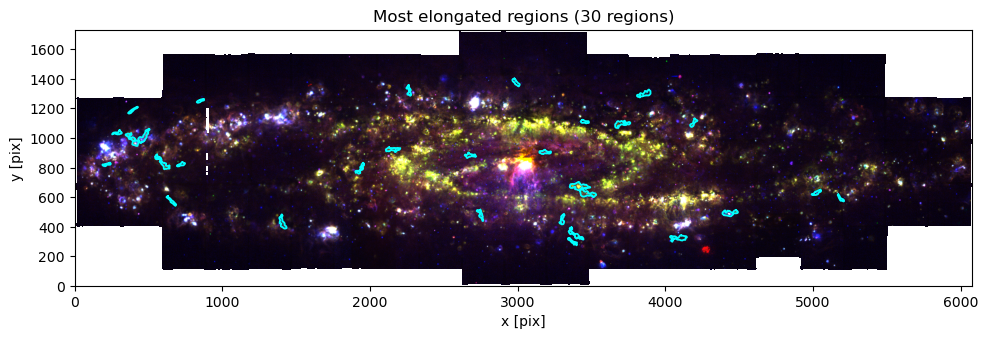

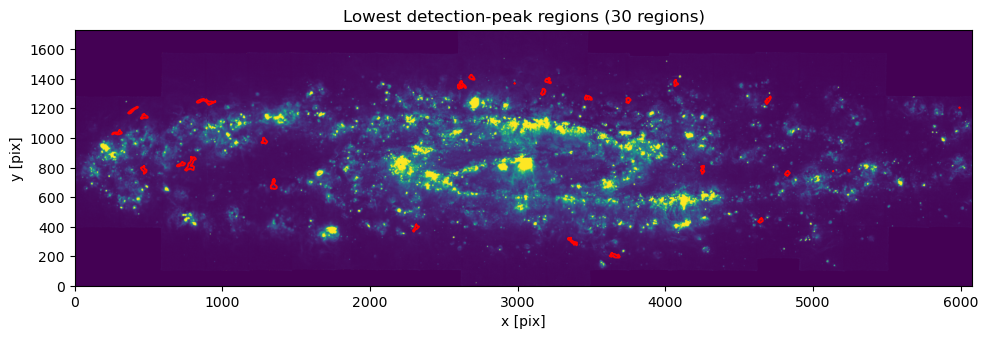

In [35]:
plot_region_contours(rgb, labels_data, elongated_regions,
    "Most elongated regions", contour_color="cyan")
plot_region_contours(percentile_norm(detection), labels_data, 
    low_peak_regions, "Lowest detection-peak regions", contour_color="red")

In [36]:
qa2 = qa.copy()

MIN_NPIX = 10
MIN_DET_PEAK = 3.0
MIN_SNR = 3.0
MAX_ELONGATION = 5.0
large_npix_cut = qa2["npix"].quantile(0.98)

qa2["flag_too_small"] = qa2["npix"] < MIN_NPIX
qa2["flag_low_peak"] = qa2["det_peak"] < MIN_DET_PEAK
qa2["flag_low_SNR"] = qa2["det_median"] < MIN_SNR
qa2["flag_edge_touching"] = qa2["edge_touching"]
qa2["flag_very_elongated"] = qa2["elongation"] > MAX_ELONGATION
qa2["flag_very_large"] = qa2["npix"] > large_npix_cut
qa2["flag_pn_overlap"] = qa2["pn_overlap_frac"] > 0


qa2["flag_bad_mask"] = (qa2["flag_too_small"] | qa2["flag_low_peak"] 
                        | qa2["flag_edge_touching"] | qa2["flag_low_SNR"] )

Total regions: 644
Good candidates: 640
Bad-mask candidates: 4
Very large regions: 13
Very elongated regions: 3


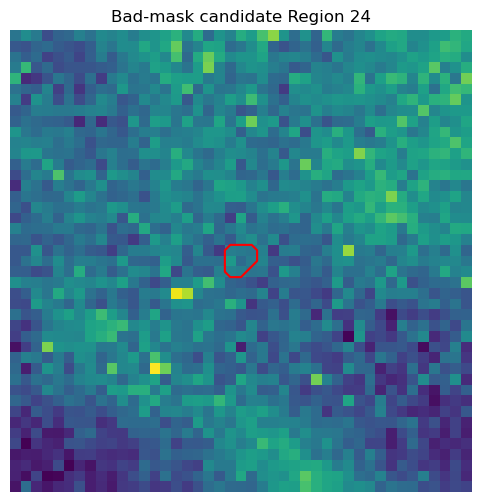

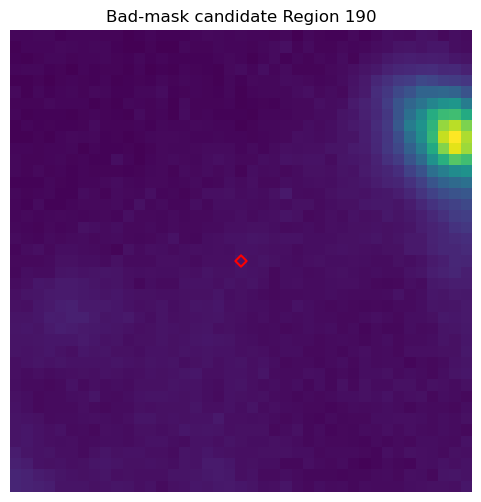

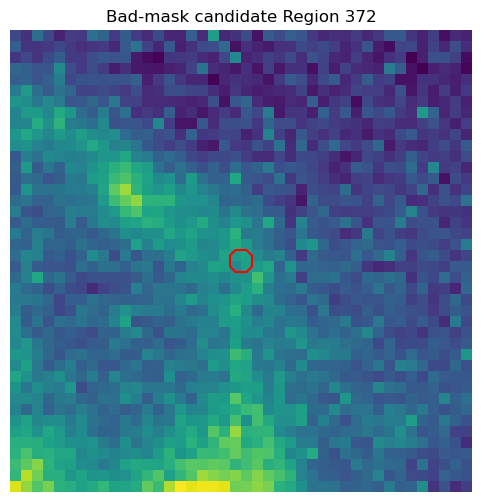

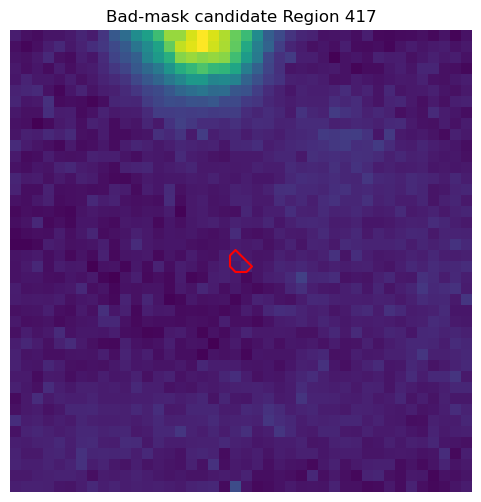

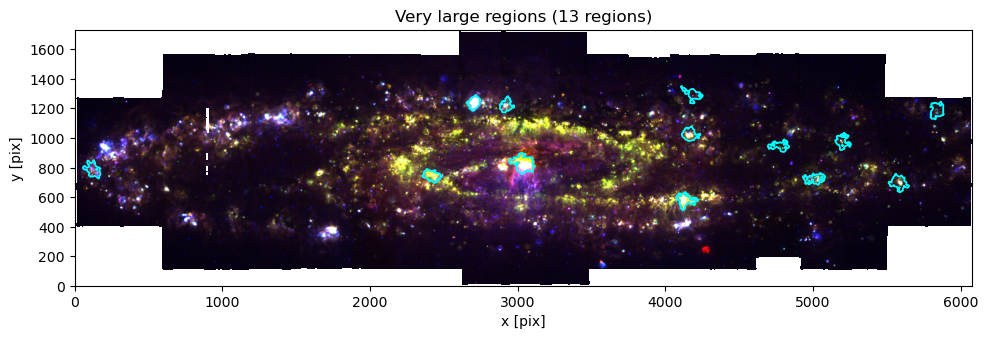

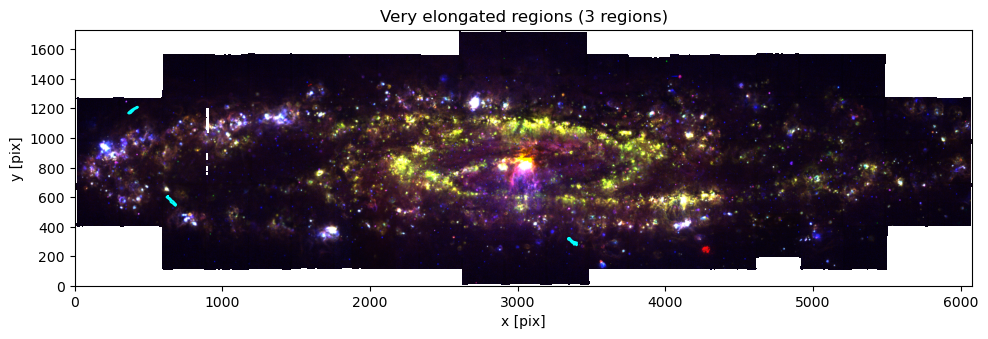

In [37]:
flag_cols = [c for c in qa2.columns if c.startswith("flag_")]

qa2[flag_cols].sum().sort_values(ascending=False)

good_candidate_ids = qa2.loc[~qa2["flag_bad_mask"], "region_id"].values
bad_candidate_ids = qa2.loc[qa2["flag_bad_mask"], "region_id"].values
large_ids = qa2.loc[qa2["flag_very_large"], "region_id"].values
elongated_ids = qa2.loc[qa2["flag_very_elongated"], "region_id"].values

print("Total regions:", len(qa2))
print("Good candidates:", len(good_candidate_ids))
print("Bad-mask candidates:", len(bad_candidate_ids))
print("Very large regions:", len(large_ids))
print("Very elongated regions:", len(elongated_ids))

for rid in bad_candidate_ids:
    plot_single_region(detection, labels_data, rid, title_prefix="Bad-mask candidate",
        contour_color="red", pad=20)
    
plot_region_contours(rgb, labels_data, large_ids, "Very large regions",
                     contour_color="cyan")

plot_region_contours(rgb, labels_data, elongated_ids[:50], 
                     "Very elongated regions", contour_color="cyan")

In [38]:
label_slices = ndi.find_objects(labels_data)

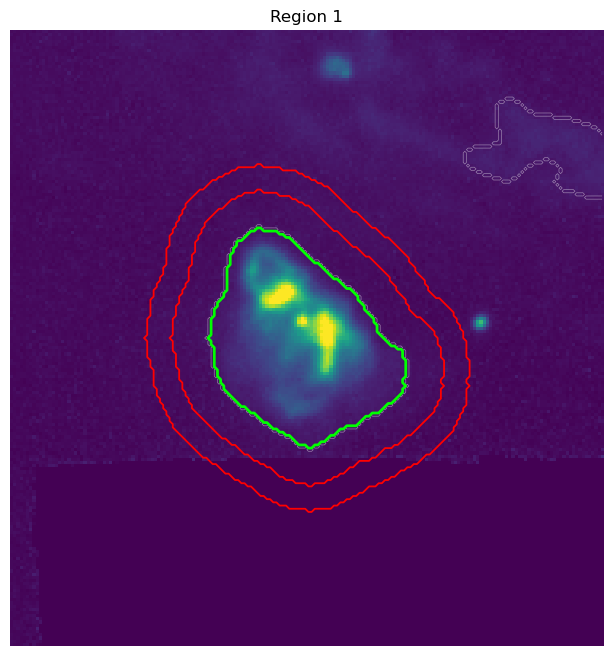

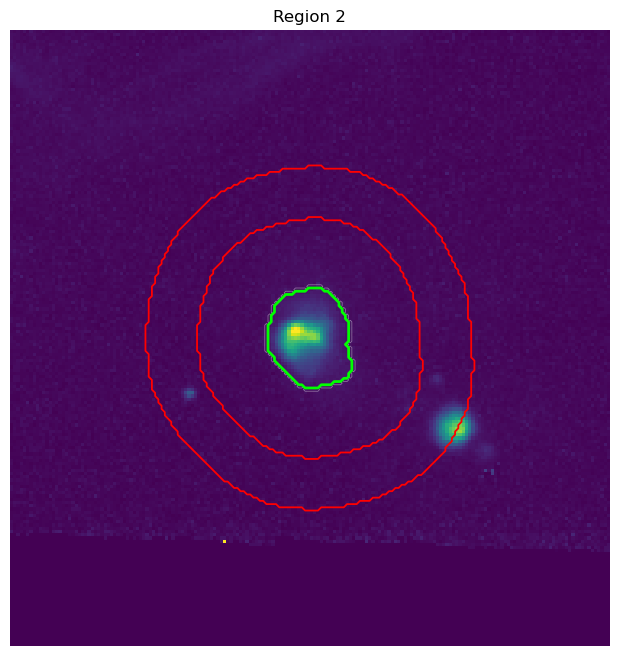

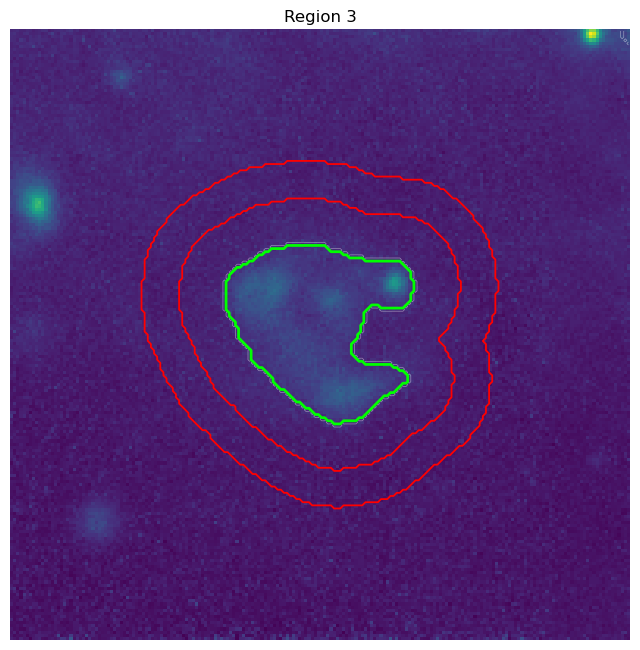

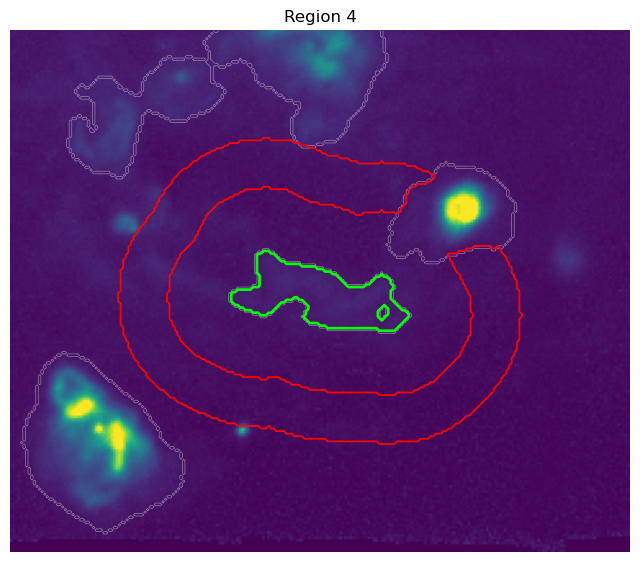

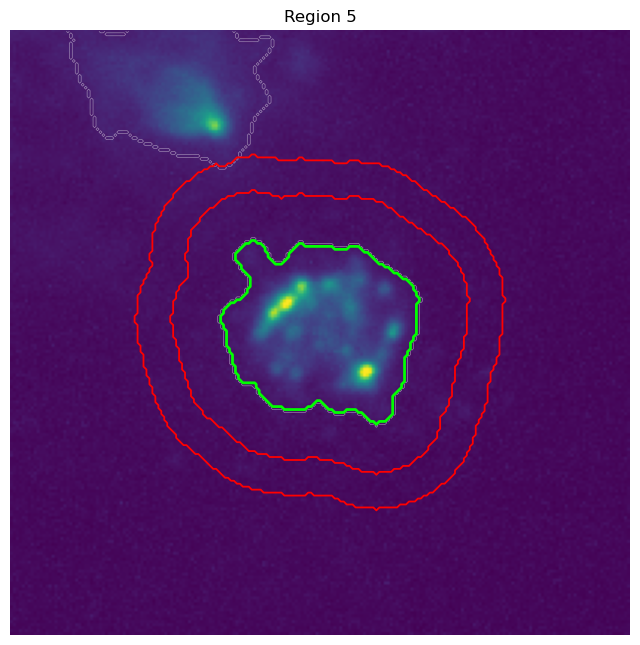

In [54]:
for test_id in good_candidate_ids[:5]:
    src_crop, ann_crop, slc = make_local_annulus(
    labels_data, test_id, qa2, label_slices, 
    inner_factor = 0.8, outer_factor = 1.4)

    show_source_annulus(percentile_norm(detection), src_crop,
    ann_crop, slc,
    labels_data=labels_data,
    title=f"Region {test_id}",
    show_all_regions=True, pad=40)

In [40]:
line_maps = {"ha": ha, "oiii": oiii, "sii": sii, "hb": hb, "nii": nii}
line_err_maps = {"ha": ha_err, "oiii": oiii_err, "sii": sii_err, "hb": hb_err, "nii": nii_err}

In [41]:
def robust_background_stats(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return np.nan, np.nan, np.nan, 0

    med = np.nanmedian(values)

    mad = np.nanmedian(np.abs(values - med))
    robust_sigma = 1.4826 * mad

    if not np.isfinite(robust_sigma) or robust_sigma == 0:
        robust_sigma = np.nanstd(values)

    # Approximate standard error of the median
    med_err = 1.253 * robust_sigma / np.sqrt(values.size)

    return med, robust_sigma, med_err, values.size

In [59]:
def extract_region_fluxes(labels_data, region_id, qa_lookup,
    label_slices, line_maps, line_err_maps,
    inner_factor, outer_factor, min_annulus_pix=20):
    
    src_crop, ann_crop, slc = make_local_annulus(labels_data,
        region_id, qa_lookup, label_slices,
        inner_factor=inner_factor, outer_factor=outer_factor)

    if src_crop is None:
        return None

    n_src = int(np.sum(src_crop))
    n_ann = int(np.sum(ann_crop))

    result = {"region_id": region_id, "n_src_pix": n_src,
        "n_ann_pix": n_ann, "flag_bad_annulus": n_ann < min_annulus_pix,}

    for line_name, img in line_maps.items():
        img_crop = img[slc]

        src_vals = img_crop[src_crop]
        ann_vals = img_crop[ann_crop]

        raw_flux = np.nansum(src_vals)

        bg_level, bg_sigma, bg_level_err, n_bg = robust_background_stats(ann_vals)

        bg_flux = bg_level * n_src
        bg_flux_err = bg_level_err * n_src

        corr_flux = raw_flux - bg_flux

        if line_err_maps is not None and line_name in line_err_maps:
            err_crop = line_err_maps[line_name][slc]
            raw_err = np.sqrt(np.nansum(err_crop[src_crop] ** 2))
        else:
            raw_err = np.nan

        corr_err = np.sqrt(raw_err**2 + bg_flux_err**2)

        result[f"{line_name}_raw_flux"] = raw_flux
        result[f"{line_name}_raw_err"] = raw_err
        result[f"{line_name}_raw_sn"] = raw_flux / raw_err if raw_err > 0 else np.nan

        result[f"{line_name}_bg_level"] = bg_level
        result[f"{line_name}_bg_sigma"] = bg_sigma
        result[f"{line_name}_bg_flux"] = bg_flux
        result[f"{line_name}_bg_flux_err"] = bg_flux_err
        result[f"{line_name}_bg_fraction"] = bg_flux / raw_flux if raw_flux != 0 else np.nan

        result[f"{line_name}_corr_flux"] = corr_flux
        result[f"{line_name}_corr_err"] = corr_err
        result[f"{line_name}_corr_sn"] = corr_flux / corr_err if corr_err > 0 else np.nan

    return result

In [60]:
qa_lookup = qa2.set_index("region_id")

rows = []
for region_id in tqdm(good_candidate_ids):
    row = extract_region_fluxes(labels_data,
        region_id, qa_lookup, label_slices,
        line_maps, line_err_maps=line_err_maps,
        inner_factor=0.8, outer_factor=1.4,
        min_annulus_pix=30)
    if row is not None:
        rows.append(row)

flux_cat = pd.DataFrame(rows)
flux_cat.head()

  0%|          | 0/640 [00:00<?, ?it/s]

,region_id,n_src_pix,n_ann_pix,flag_bad_annulus,ha_raw_flux,ha_raw_err,ha_raw_sn,ha_bg_level,ha_bg_sigma,ha_bg_flux,...,nii_raw_err,nii_raw_sn,nii_bg_level,nii_bg_sigma,nii_bg_flux,nii_bg_flux_err,nii_bg_fraction,nii_corr_flux,nii_corr_err,nii_corr_sn
0,1,2705,7265,False,4.136284e+06,2230.984131,1854.017700,155.789307,99.750101,421410.074463,...,1225.067505,900.532898,103.184448,48.879554,279113.932495,2327.165491,0.253001,824099.692505,2629.921975,313.355187
1,2,628,1549,False,8.595512e+05,1018.135925,844.240173,101.955505,51.384139,64028.057373,...,534.740051,388.732971,41.358131,35.731438,25972.906525,714.390224,0.124947,181898.187225,892.356616,203.840240
2,3,2226,5965,False,1.046008e+06,1294.025879,808.336060,162.110870,56.452275,360858.797424,...,924.635925,431.834442,95.132042,39.896036,211763.925339,1440.790234,0.530352,187525.699661,1711.966157,109.538205
3,4,1089,3288,False,5.050188e+05,883.688354,571.489746,188.391518,88.309738,205158.362709,...,653.859131,342.123962,113.027054,43.577623,123086.461624,1036.994811,0.550228,100614.413376,1225.924137,82.072300
4,5,3017,7766,False,8.227971e+05,1846.794067,445.527283,137.015656,74.334973,413376.232697,...,1142.043213,123.069855,88.854214,47.992241,268073.162777,2058.726805,1.907300,-127522.069027,2354.276706,-54.166135


In [64]:
suspicious_bg = flux_cat[
    (flux_cat["oiii_bg_fraction"] > 0.9) |
    (flux_cat["flag_bad_annulus"])]["region_id"].values

len(suspicious_bg)

26

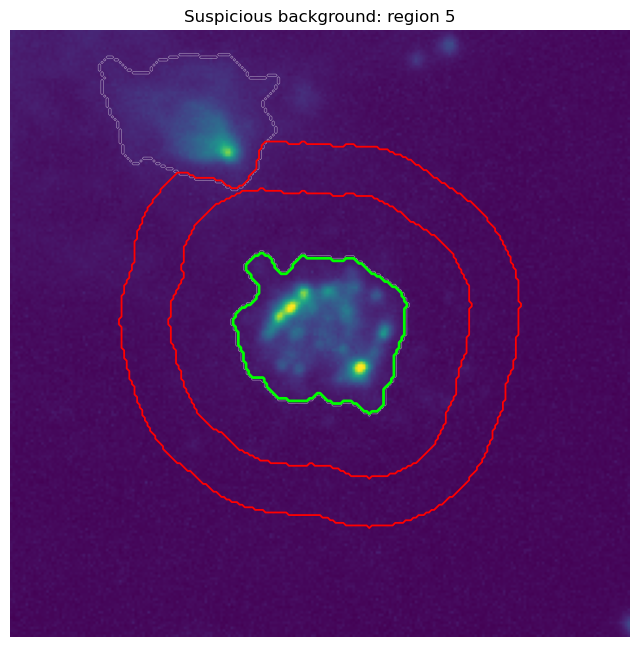

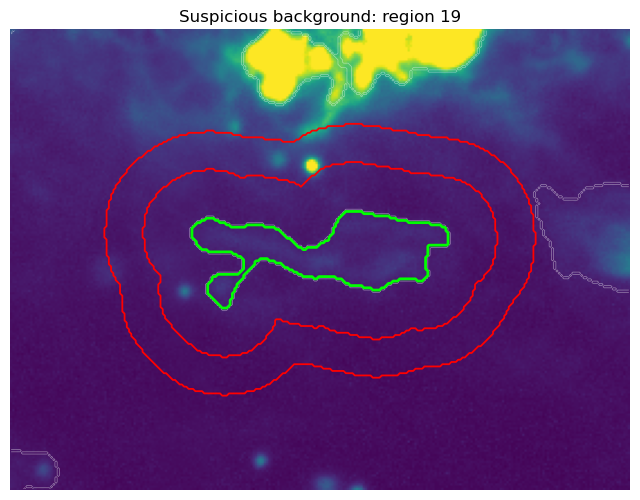

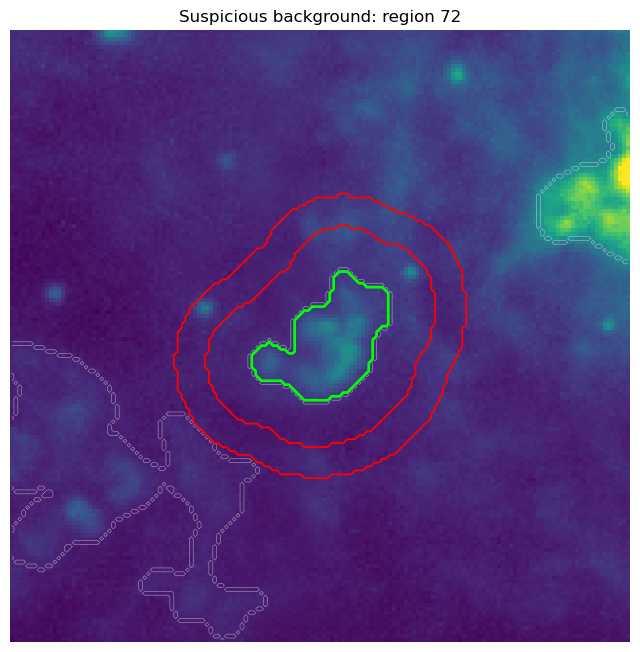

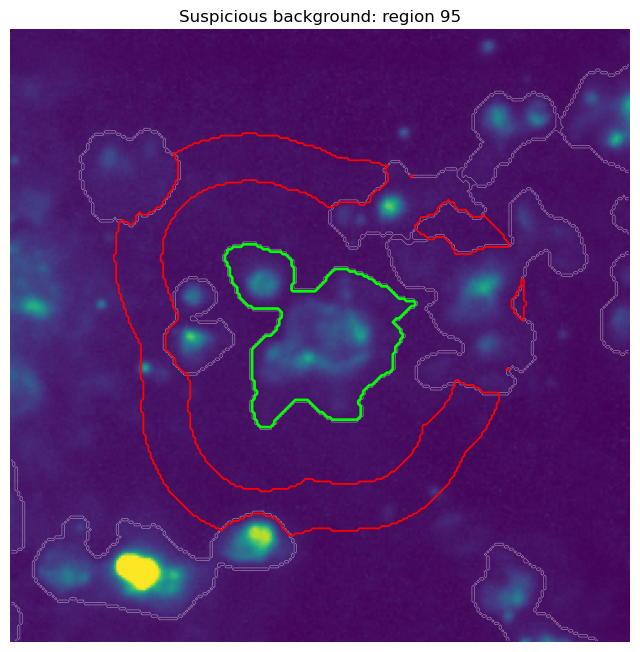

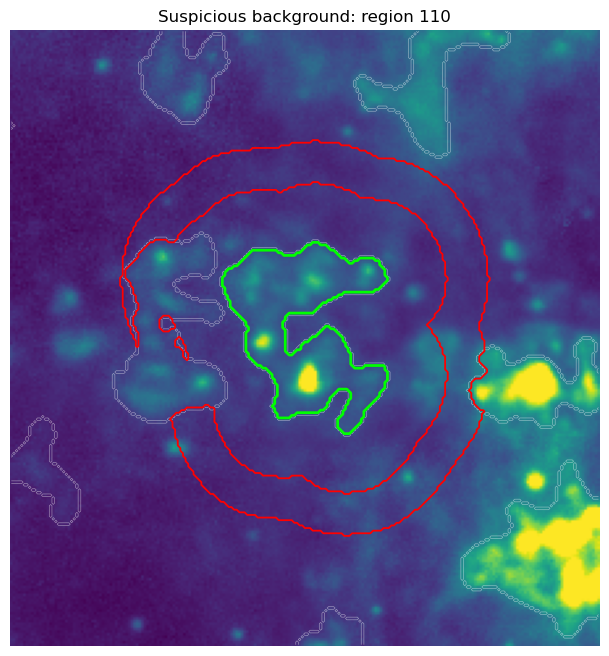

In [65]:
for region_id in suspicious_bg[:5]:
    src_crop, ann_crop, slc = make_local_annulus(labels_data,
        region_id, qa_lookup, label_slices, inner_factor = 0.8,
    outer_factor = 1.4)

    show_source_annulus(percentile_norm(detection),
        src_crop, ann_crop, slc,
        labels_data=labels_data,
        title=f"Suspicious background: region {region_id}",
        show_all_regions=True, pad=40)

In [66]:
cat = qa2.merge(flux_cat, on="region_id", how="left")

print("QA regions:", len(qa2))
print("Flux regions:", len(flux_cat))
print("Merged catalogue:", len(cat))

QA regions: 644
Flux regions: 640
Merged catalogue: 644


In [68]:
cat["flag_high_ha_bg"] = cat["ha_bg_fraction"] > 0.9
cat["flag_high_oiii_bg"] = cat["oiii_bg_fraction"] > 0.9
cat["flag_high_sii_bg"] = cat["sii_bg_fraction"] > 0.9

cat["flag_any_high_bg"] = (cat["flag_high_ha_bg"] |
    cat["flag_high_oiii_bg"] |
    cat["flag_high_sii_bg"])

cat[["flag_bad_annulus",
    "flag_high_ha_bg",
    "flag_high_oiii_bg",
    "flag_high_sii_bg",
    "flag_any_high_bg"]].sum()

flag_bad_annulus      0
flag_high_ha_bg       6
flag_high_oiii_bg    26
flag_high_sii_bg     13
flag_any_high_bg     37
dtype: object

In [69]:
def safe_log10_ratio(num, den):
    num = np.asarray(num, dtype=float)
    den = np.asarray(den, dtype=float)

    out = np.full_like(num, np.nan, dtype=float)

    valid = (
        np.isfinite(num) &
        np.isfinite(den) &
        (num > 0) &
        (den > 0))

    out[valid] = np.log10(num[valid] / den[valid])
    return out

In [70]:
cat["log_sii_ha_raw"] = safe_log10_ratio(cat["sii_raw_flux"], cat["ha_raw_flux"])

cat["log_oiii_ha_raw"] = safe_log10_ratio(cat["oiii_raw_flux"], cat["ha_raw_flux"])

cat["log_sii_oiii_raw"] = safe_log10_ratio(cat["sii_raw_flux"], cat["oiii_raw_flux"])

cat["log_sii_ha_corr"] = safe_log10_ratio(cat["sii_corr_flux"], cat["ha_corr_flux"])

cat["log_oiii_ha_corr"] = safe_log10_ratio(cat["oiii_corr_flux"], cat["ha_corr_flux"])

cat["log_sii_oiii_corr"] = safe_log10_ratio(cat["sii_corr_flux"], cat["oiii_corr_flux"])

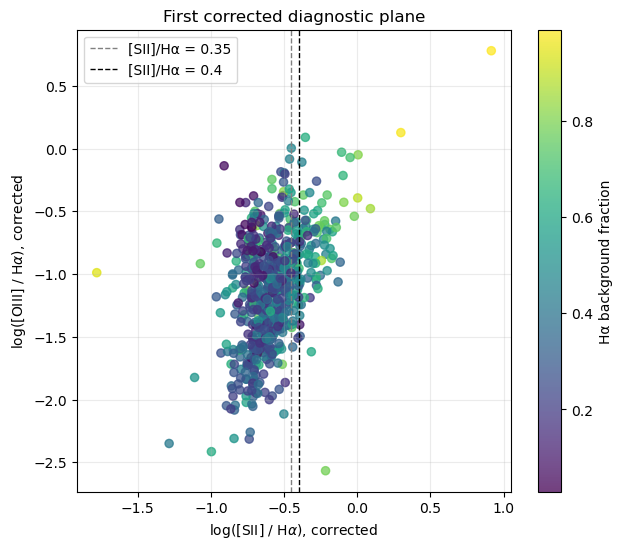

In [74]:
plot_cat = cat[(~cat["flag_bad_mask"]) &
    np.isfinite(cat["log_sii_ha_corr"]) &
    np.isfinite(cat["log_oiii_ha_corr"])].copy()

plt.figure(figsize=(7, 6))

plt.scatter(
    plot_cat["log_sii_ha_corr"],
    plot_cat["log_oiii_ha_corr"],
    s=35, alpha=0.75,
    c=plot_cat["ha_bg_fraction"])

plt.colorbar(label="Hα background fraction")

plt.axvline(np.log10(0.35), color="gray", linestyle="--", linewidth=1, label="[SII]/Hα = 0.35")
plt.axvline(np.log10(0.4), color="black", linestyle="--", linewidth=1, label="[SII]/Hα = 0.4")

plt.xlabel(r"log([SII] / H$\alpha$), corrected")
plt.ylabel(r"log([OIII] / H$\alpha$), corrected")
plt.title("First corrected diagnostic plane")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

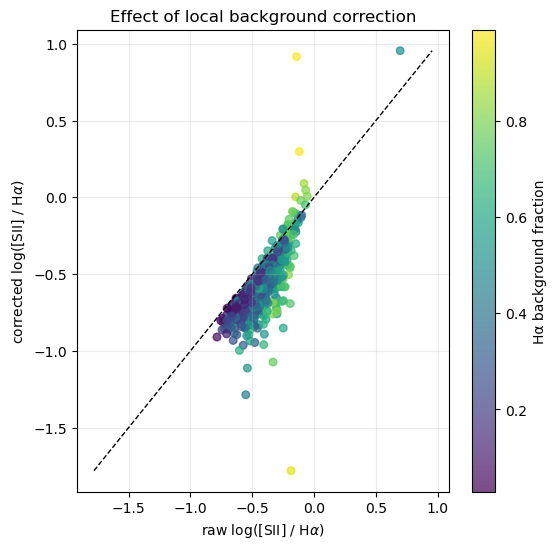

In [75]:
plt.figure(figsize=(6, 6))

valid = (np.isfinite(cat["log_sii_ha_raw"]) &
    np.isfinite(cat["log_sii_ha_corr"]))

plt.scatter(
    cat.loc[valid, "log_sii_ha_raw"],
    cat.loc[valid, "log_sii_ha_corr"],
    s=30, alpha=0.7,
    c=cat.loc[valid, "ha_bg_fraction"])

plt.colorbar(label="Hα background fraction")

lims = [np.nanmin([cat["log_sii_ha_raw"].min(), cat["log_sii_ha_corr"].min()]),
    np.nanmax([cat["log_sii_ha_raw"].max(), cat["log_sii_ha_corr"].max()])]

plt.plot(lims, lims, color="black", linestyle="--", linewidth=1)

plt.xlabel(r"raw log([SII] / H$\alpha$)")
plt.ylabel(r"corrected log([SII] / H$\alpha$)")
plt.title("Effect of local background correction")
plt.grid(alpha=0.25)
plt.show()

In [76]:
suspicious_ids = cat.loc[cat["flag_any_high_bg"], "region_id"].values

print("Suspicious/high-background regions:", len(suspicious_ids))
suspicious_ids[:30]

Suspicious/high-background regions: 37


array([  5,  18,  19,  36,  72,  95, 110, 113, 115, 147, 151, 156, 161,
       162, 192, 193, 208, 216, 221, 231, 240, 277, 281, 286, 291, 305,
       311, 315, 320, 340])

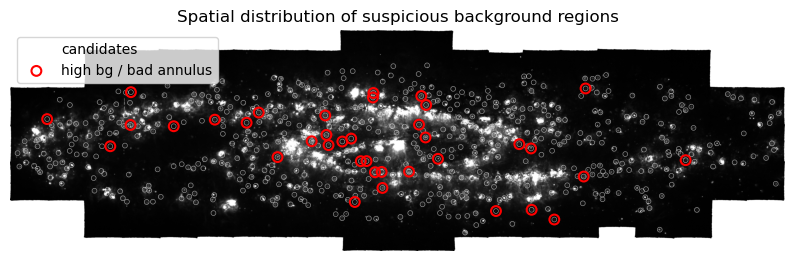

In [77]:
plt.figure(figsize=(10, 10))

plt.imshow(percentile_norm(ha), origin="lower", cmap="gray")

plt.scatter(
    cat.loc[~cat["flag_bad_mask"], "x"],
    cat.loc[~cat["flag_bad_mask"], "y"],
    s=12,
    facecolors="none",
    edgecolors="white",
    linewidths=0.5,
    alpha=0.5,
    label="candidates")

sus = cat["flag_any_high_bg"] & (~cat["flag_bad_mask"])

plt.scatter(
    cat.loc[sus, "x"],
    cat.loc[sus, "y"],
    s=50,
    facecolors="none",
    edgecolors="red",
    linewidths=1.5,
    label="high bg / bad annulus")

plt.legend()
plt.title("Spatial distribution of suspicious background regions")
plt.axis("off")
plt.show()

In [78]:
cat2 = cat.copy()

# Linear corrected ratios
cat2["sii_ha_corr"] = 10 ** cat2["log_sii_ha_corr"]
cat2["oiii_ha_corr"] = 10 ** cat2["log_oiii_ha_corr"]
cat2["sii_oiii_corr"] = 10 ** cat2["log_sii_oiii_corr"]

# Corrected Halpha surface brightness inside the segmentation mask
cat2["ha_corr_sb"] = cat2["ha_corr_flux"] / cat2["area_arcsec2"]

# Only use positive corrected Halpha surface brightness for quantiles
positive_sb = cat2.loc[
    np.isfinite(cat2["ha_corr_sb"]) & (cat2["ha_corr_sb"] > 0),
    "ha_corr_sb"
]

LOW_HA_SB_CUT = positive_sb.quantile(0.25)

print("Low Halpha surface brightness cut:", LOW_HA_SB_CUT)

Low Halpha surface brightness cut: 11526.726896734745


In [79]:
cat2["flag_ha_reliable"] = (
    np.isfinite(cat2["ha_corr_flux"]) &
    np.isfinite(cat2["ha_corr_sn"]) &
    (cat2["ha_corr_flux"] > 0) &
    (cat2["ha_corr_sn"] >= 3)
)

cat2["flag_sii_reliable"] = (
    np.isfinite(cat2["sii_corr_flux"]) &
    np.isfinite(cat2["sii_corr_sn"]) &
    (cat2["sii_corr_flux"] > 0) &
    (cat2["sii_corr_sn"] >= 3)
)

cat2["flag_oiii_reliable"] = (
    np.isfinite(cat2["oiii_corr_flux"]) &
    np.isfinite(cat2["oiii_corr_sn"]) &
    (cat2["oiii_corr_flux"] > 0) &
    (cat2["oiii_corr_sn"] >= 3)
)

cat2["flag_sii_ha_reliable"] = cat2["flag_ha_reliable"] & cat2["flag_sii_reliable"]
cat2["flag_oiii_ha_reliable"] = cat2["flag_ha_reliable"] & cat2["flag_oiii_reliable"]

In [80]:
# Approximate line-ratio thresholds
SII_HA_DIG_LIKE = 0.35
SII_HA_SHOCK_LIKE = 0.40
OIII_HA_HIGH = 1.0

# Size / shape flags
cat2["flag_compact"] = cat2["r_eq_arcsec"] <= 1.5 * psf_fwhm_arcsec
cat2["flag_low_ha_sb"] = cat2["ha_corr_sb"] < LOW_HA_SB_CUT

# Line-ratio flags
cat2["flag_hii_like_ratio"] = (
    cat2["flag_sii_ha_reliable"] &
    (cat2["sii_ha_corr"] < SII_HA_DIG_LIKE)
)

cat2["flag_high_sii"] = (
    cat2["flag_sii_ha_reliable"] &
    (cat2["sii_ha_corr"] >= SII_HA_SHOCK_LIKE)
)

cat2["flag_moderate_sii"] = (
    cat2["flag_sii_ha_reliable"] &
    (cat2["sii_ha_corr"] >= SII_HA_DIG_LIKE) &
    (cat2["sii_ha_corr"] < SII_HA_SHOCK_LIKE)
)

cat2["flag_high_oiii"] = (
    cat2["flag_oiii_ha_reliable"] &
    (cat2["oiii_ha_corr"] >= OIII_HA_HIGH)
)

In [81]:
cat2["first_pass_tag"] = "unclassified_initial"

# Bad masks or bad annuli should not be trusted yet
cat2.loc[
    cat2["flag_bad_mask"] | cat2["flag_any_high_bg"],
    "first_pass_tag"
] = "needs_inspection"

# Diffuse / DIG-like candidates
cat2.loc[
    (~cat2["flag_bad_mask"]) &
    cat2["flag_high_sii"] &
    (
        cat2["flag_low_ha_sb"] |
        cat2["flag_very_large"] |
        cat2["flag_very_elongated"]
    ),
    "first_pass_tag"
] = "dig_or_filament_candidate"

# SNR/shock-like candidates
cat2.loc[
    (~cat2["flag_bad_mask"]) &
    (~cat2["flag_any_high_bg"]) &
    cat2["flag_high_sii"] &
    (~cat2["flag_low_ha_sb"]),
    "first_pass_tag"
] = "snr_or_shock_candidate"

# High-OIII compact candidates: possible PN or compact high-excitation nebula
cat2.loc[
    (~cat2["flag_bad_mask"]) &
    (~cat2["flag_any_high_bg"]) &
    cat2["flag_high_oiii"] &
    cat2["flag_compact"],
    "first_pass_tag"
] = "compact_high_oiii_candidate"

# HII-like candidates
cat2.loc[
    (~cat2["flag_bad_mask"]) &
    (~cat2["flag_any_high_bg"]) &
    cat2["flag_hii_like_ratio"] &
    (~cat2["flag_low_ha_sb"]),
    "first_pass_tag"
] = "hii_like_candidate"

# Moderate [SII]/Halpha: uncertain transition region
cat2.loc[
    (~cat2["flag_bad_mask"]) &
    (~cat2["flag_any_high_bg"]) &
    cat2["flag_moderate_sii"],
    "first_pass_tag"
] = "transition_sii_candidate"

In [82]:
cat2["first_pass_tag"].value_counts()

first_pass_tag
hii_like_candidate           417
unclassified_initial          63
dig_or_filament_candidate     59
transition_sii_candidate      42
needs_inspection              37
snr_or_shock_candidate        26
Name: count, dtype: int64

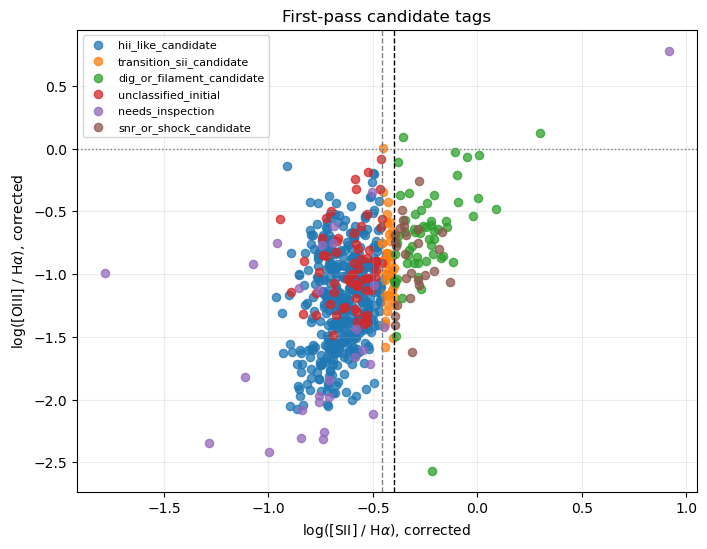

In [84]:
plot_cat = cat2[
    (~cat2["flag_bad_mask"]) &
    np.isfinite(cat2["log_sii_ha_corr"]) &
    np.isfinite(cat2["log_oiii_ha_corr"])
].copy()

plt.figure(figsize=(8, 6))

for tag in plot_cat["first_pass_tag"].unique():
    sub = plot_cat[plot_cat["first_pass_tag"] == tag]

    plt.scatter(
        sub["log_sii_ha_corr"],
        sub["log_oiii_ha_corr"],
        s=35,
        alpha=0.75,
        label=tag
    )

plt.axvline(np.log10(0.35), color="gray", linestyle="--", linewidth=1)
plt.axvline(np.log10(0.40), color="black", linestyle="--", linewidth=1)
plt.axhline(np.log10(1.0), color="gray", linestyle=":", linewidth=1)

plt.xlabel(r"log([SII] / H$\alpha$), corrected")
plt.ylabel(r"log([OIII] / H$\alpha$), corrected")
plt.title("First-pass candidate tags")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.show()